# Dataset B — XGBoost final reporting

Notebook cung cấp một publication helper không tự chạy; các reporting cells chỉ đọc package được tạo từ frozen XGB-10 evidence. Không có bước huấn luyện, refit, inference, chọn lại threshold hoặc dùng historical XGBoost result làm kết quả cuối.

## Final lifecycle stage map

- **XGB-07 — training:** Train-only cross-validation và fresh full-Train fit; được thực thi ngoài notebook này.
- **XGB-08 — Validation threshold:** một lần inference trên Validation và khóa threshold; được thực thi ngoài notebook này.
- **XGB-09 — Test evaluation:** một lần inference trên Test bằng frozen threshold và tạo evaluation evidence; được thực thi ngoài notebook này.
- **XGB-10 — final review:** review chỉ đọc đối với evidence XGB-07/08/09 và đóng băng bundle đã PASS.
- **XGB-11 — reporting:** tạo và validate reporting package chỉ từ frozen XGB-10 evidence; không nối historical result vào final reporting.
- **XGB-12 — publication:** publication helper chỉ được định nghĩa tại đây; notebook không tự gọi helper hoặc chạy publication.

Một `run_id` duy nhất phải được giữ nguyên qua mọi stage và ba root preprocessing/working/final. Placeholder chỉ được thay bằng exact final run ID sau khi XGB-01 preflight xác nhận ID chưa tồn tại. Không xóa partial artifact để chạy lại cùng ID, không tự tạo attempt khác, và không vá source/config/test sau khi XGB-00V PASS. Nếu execution phát hiện lỗi source hoặc contract, dừng toàn bộ run và giữ evidence thất bại.

## Publication boundary

Hàm publication bên dưới không tự chạy. Trước khi di chuyển, nó validate toàn bộ working bundle và reporting package, từ chối overwrite, sau đó thực hiện một atomic directory operation và validate lại reporting package tại final destination.

In [1]:
import os
from pathlib import Path
import sys

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'config/dataset_b/model_protocol_v1.yaml').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot locate the Dataset B project root.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_b.reporting import validate_reporting_directory
from src.dataset_b.review.xgb_final_review import review_xgb_final

def publish_xgboost_final(
    run_id: str,
    *,
    working_root: str | Path,
    final_root: str | Path,
    bundle_validator=review_xgb_final,
    reporting_validator=validate_reporting_directory,
) -> Path:
    if not isinstance(run_id, str) or not run_id or run_id in {'.', '..'}:
        raise ValueError('Publication requires an explicit valid run_id.')
    working_root = Path(working_root).resolve(strict=True)
    final_root = Path(final_root).resolve(strict=True)
    working_dir = (working_root / run_id).resolve(strict=True)
    destination = final_root / run_id
    if working_dir.parent != working_root:
        raise ValueError('Working bundle escaped the authorized root.')
    if destination.exists():
        raise FileExistsError(f'Final XGBoost destination already exists: {destination}')
    if working_dir.stat().st_dev != final_root.stat().st_dev:
        raise OSError('Atomic publication requires working and final roots on the same filesystem.')

    bundle = bundle_validator(run_id, run_dir=working_dir)
    working_summary = reporting_validator(working_dir / 'reporting')
    if bundle.get('status') != 'PASS' or bundle.get('run_id') != run_id:
        raise ValueError('Working XGBoost bundle is incomplete or misaligned.')
    if (
        working_summary.get('reporting_status') != 'COMPLETE'
        or working_summary.get('run_id') != run_id
        or working_summary.get('model_key') != 'xgboost'
    ):
        raise ValueError('Working XGBoost reporting package is incomplete or misaligned.')

    # Validators return materialized values and close their own file contexts before this operation.
    os.replace(working_dir, destination)
    final_summary = reporting_validator(destination / 'reporting')
    if (
        final_summary.get('reporting_status') != 'COMPLETE'
        or final_summary.get('run_id') != run_id
        or final_summary.get('model_key') != 'xgboost'
    ):
        raise ValueError('Published XGBoost reporting package failed final revalidation.')
    return destination

In [2]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'config/dataset_b/model_protocol_v1.yaml').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot locate the Dataset B project root.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_b.reporting import validate_reporting_directory

RUN_ID = 'xgb_final_15f_20261003_01'
if RUN_ID.startswith('SET_'):
    raise RuntimeError('Set RUN_ID to the approved XGBoost final run before rendering.')
REPORTING_DIR = PROJECT_ROOT / 'artifacts/dataset_b/xgboost/final' / RUN_ID / 'reporting'
report_summary = validate_reporting_directory(REPORTING_DIR)
if report_summary['model_key'] != 'xgboost' or report_summary.get('protocol_model_key') != 'xgb':
    raise ValueError('Reporting package is not the approved XGBoost key mapping.')
print(f"Loaded frozen XGBoost reporting package: {RUN_ID}")

Loaded frozen XGBoost reporting package: xgb_final_15f_20261003_01


## Frozen reporting charts

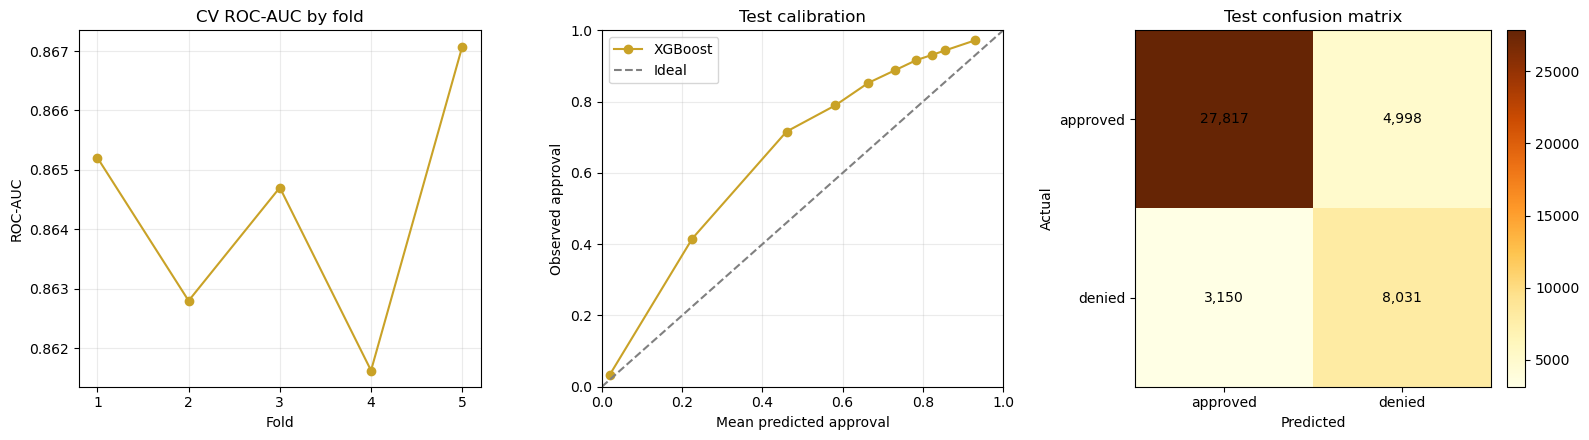

In [3]:
import matplotlib.pyplot as plt

cv_folds = pd.read_csv(REPORTING_DIR / 'cv_fold_metrics.csv')
confusion = pd.read_csv(REPORTING_DIR / 'confusion_matrix.csv')
calibration = pd.read_csv(REPORTING_DIR / 'calibration_curve.csv')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(cv_folds['fold'], cv_folds['roc_auc'], marker='o', color='#C9A227')
axes[0].set(title='CV ROC-AUC by fold', xlabel='Fold', ylabel='ROC-AUC', xticks=cv_folds['fold'])
axes[0].grid(alpha=0.25)

axes[1].plot(calibration['mean_p_approved'], calibration['observed_approval_rate'], marker='o', color='#C9A227', label='XGBoost')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Ideal')
axes[1].set(title='Test calibration', xlabel='Mean predicted approval', ylabel='Observed approval', xlim=(0, 1), ylim=(0, 1))
axes[1].legend()
axes[1].grid(alpha=0.25)

matrix = confusion.pivot(index='actual_class', columns='predicted_class', values='count').reindex(index=['approved', 'denied'], columns=['approved', 'denied'])
image = axes[2].imshow(matrix.to_numpy(), cmap='YlOrBr')
axes[2].set(title='Test confusion matrix', xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1], xticklabels=matrix.columns, yticklabels=matrix.index)
for row in range(2):
    for column in range(2):
        axes[2].text(column, row, f'{int(matrix.iloc[row, column]):,}', ha='center', va='center')
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

## Frozen lineage and results

In [4]:
lineage = pd.DataFrame([
    {'Field': 'Reporting model key', 'Value': report_summary['model_key']},
    {'Field': 'Protocol model key', 'Value': report_summary['protocol_model_key']},
    {'Field': 'run_id', 'Value': report_summary['run_id']},
    {'Field': 'Feature version', 'Value': report_summary['feature_version']},
    {'Field': 'Split version', 'Value': report_summary['split_version']},
    {'Field': 'Preprocessing version', 'Value': report_summary['preprocessing_version']},
])
cv_folds = pd.read_csv(REPORTING_DIR / 'cv_fold_metrics.csv')
rq1_metrics = pd.read_csv(REPORTING_DIR / 'rq1_metrics_long.csv')
confusion = pd.read_csv(REPORTING_DIR / 'confusion_matrix.csv')
calibration = pd.read_csv(REPORTING_DIR / 'calibration_curve.csv')
display(lineage)
display(cv_folds)
display(rq1_metrics)
display(confusion)
display(calibration)

,Field,Value
0,Reporting model key,xgboost
1,Protocol model key,xgb
2,run_id,xgb_final_15f_20261003_01
3,Feature version,feature_set_v1
4,Split version,split_v1
5,Preprocessing version,dataset_b_preprocessing_v2


,model_key,run_id,feature_version,split_version,fold,roc_auc,fit_seconds,predict_seconds,warning_count
0,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,1,0.865205,1.405844,0.019546,0
1,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,2,0.862796,0.331874,0.013871,0
2,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,3,0.864702,0.330154,0.012119,0
3,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,4,0.861622,0.335002,0.011116,0
4,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,5,0.867076,0.388700,0.013362,0


,model_key,run_id,feature_version,split_version,partition,metric,estimate,ci_low,ci_high,unit,higher_is_better,valid_replicates
0,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,average_precision_denied,0.780825,0.774897,0.786547,rate,True,1000
1,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,balanced_accuracy,0.782982,0.778379,0.787234,rate,True,1000
2,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,brier_score_approved,0.131388,0.129876,0.133054,rate,False,1000
3,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,calibration_intercept,1.022455,1.005219,1.039434,coefficient,False,1000
4,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,calibration_slope,1.060978,1.038072,1.083572,coefficient,False,1000
5,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,f1_denied,0.663445,0.657144,0.669398,rate,True,1000
6,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,precision_denied,0.616394,0.609510,0.622759,rate,True,1000
7,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,recall_approved,0.847692,0.843637,0.851380,rate,True,1000
8,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,recall_denied,0.718272,0.709865,0.726145,rate,True,1000
9,xgboost,xgb_final_15f_20261003_01,feature_set_v1,split_v1,test,roc_auc_approved,0.864146,0.859808,0.868027,rate,True,1000


,model_key,run_id,actual_class,predicted_class,count
0,xgboost,xgb_final_15f_20261003_01,approved,approved,27817
1,xgboost,xgb_final_15f_20261003_01,approved,denied,4998
2,xgboost,xgb_final_15f_20261003_01,denied,approved,3150
3,xgboost,xgb_final_15f_20261003_01,denied,denied,8031


,model_key,run_id,bin,lower_edge,upper_edge,count,mean_p_approved,observed_approval_rate
0,xgboost,xgb_final_15f_20261003_01,0,0.000048,0.065089,4400,0.019890,0.033864
1,xgboost,xgb_final_15f_20261003_01,1,0.065089,0.376789,4399,0.225243,0.415549
2,xgboost,xgb_final_15f_20261003_01,2,0.376789,0.529163,4400,0.460138,0.715909
3,xgboost,xgb_final_15f_20261003_01,3,0.529163,0.628043,4399,0.581374,0.789270
4,xgboost,xgb_final_15f_20261003_01,4,0.628043,0.698315,4400,0.663816,0.852500
5,xgboost,xgb_final_15f_20261003_01,5,0.698315,0.759190,4399,0.730277,0.887929
6,xgboost,xgb_final_15f_20261003_01,6,0.759190,0.805180,4400,0.783549,0.916364
7,xgboost,xgb_final_15f_20261003_01,7,0.805180,0.840242,4399,0.823415,0.931348
8,xgboost,xgb_final_15f_20261003_01,8,0.840242,0.871734,4400,0.855323,0.943636
9,xgboost,xgb_final_15f_20261003_01,9,0.871734,0.999953,4400,0.930873,0.972273


## Reporting boundary

Mọi bảng trong notebook đến từ sáu reporting files đã validate. Kết quả lịch sử không được nối vào summary này; so sánh sáu model vẫn là một gate riêng.